In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/MODEL_CARD.md
/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/model_config.json
/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/threshold_sweep.png
/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/threshold_sweep.csv
/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/training_history.csv
/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/best.pt
/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/LZ46LTL6O2.jpg
/kaggle/input/competitions/industrial

In [2]:
from pathlib import Path
import pandas as pd

# Find the competition's sample submission file
matches = list(
    Path("/kaggle/input").rglob("sample_submission.csv")
)

if not matches:
    raise FileNotFoundError(
        "sample_submission.csv not found. "
        "Check whether the competition data is attached."
    )

sample_path = matches[0]
print("Using:", sample_path)

# Read the official submission template
sample = pd.read_csv(sample_path, keep_default_na=False)

print("Columns:", sample.columns.tolist())
print("Template shape:", sample.shape)

# Verify the required submission columns
required = ["ID", "image_id", "defect_type", "mask_rle"]

missing = [col for col in required if col not in sample.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Create dummy predictions: no predicted defects
submission = sample.copy()
submission["mask_rle"] = " "

# Save the submission
output_path = Path("/kaggle/working/dummy_submission.csv")
submission.to_csv(output_path, index=False)

print("\nDummy submission created successfully!")
print("Rows:", len(submission))
print("Columns:", submission.columns.tolist())
print("Unique images:", submission["image_id"].nunique())
print("Defect categories:", submission["defect_type"].nunique())
print("Saved to:", output_path)

display(submission.head(8))

Using: /kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
Template shape: (12000, 4)

Dummy submission created successfully!
Rows: 12000
Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
Unique images: 3000
Defect categories: 4
Saved to: /kaggle/working/dummy_submission.csv


,ID,image_id,defect_type,mask_rle
0,1,WAFNKCRR7Q,defect_a,
1,2,WAFNKCRR7Q,defect_b,
2,3,WAFNKCRR7Q,defect_c,
3,4,WAFNKCRR7Q,defect_d,
4,5,YZXKEWSUDD,defect_a,
5,6,YZXKEWSUDD,defect_b,
6,7,YZXKEWSUDD,defect_c,
7,8,YZXKEWSUDD,defect_d,


In [3]:

from pathlib import Path

input_dir = Path("/kaggle/input")

print("Files and folders attached to Kaggle:\n")

for path in sorted(input_dir.rglob("*")):
    if path.is_file():
        print(path)


Files and folders attached to Kaggle:

/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/00755AT0HO.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/00JDJCJDID.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/013R8BTZDO.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/01FR6RG5CM.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/02BG8UIHZU.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/02US33J1G6.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/03H0T3NNFA.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/03IEDG0ILA.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/04K05CCESG.jpg
/kaggle/input/competitions/industrial-surface-defect-detect

In [4]:
from pathlib import Path

input_dir = Path("/kaggle/input")

print("Available competition files:")

for path in sorted(input_dir.rglob("*")):
    if path.is_file() and (
        path.name.lower() in {"train.csv", "sample_submission.csv"}
        or path.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
    ):
        print(path)

Available competition files:
/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/00755AT0HO.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/00JDJCJDID.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/013R8BTZDO.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/01FR6RG5CM.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/02BG8UIHZU.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/02US33J1G6.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/03H0T3NNFA.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/03IEDG0ILA.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/04K05CCESG.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public

In [5]:

from pathlib import Path

input_dir = Path("/kaggle/input")

print("Available competition files:")

for path in sorted(input_dir.rglob("*")):
    if path.is_file() and (
        path.name.lower() in {"train.csv", "sample_submission.csv"}
        or path.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
    ):
        print(path)


Available competition files:
/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/00755AT0HO.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/00JDJCJDID.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/013R8BTZDO.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/01FR6RG5CM.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/02BG8UIHZU.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/02US33J1G6.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/03H0T3NNFA.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/03IEDG0ILA.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/04K05CCESG.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public

In [6]:

from pathlib import Path

base = Path("/kaggle/input/competitions/industrial-surface-defect-detection")

for path in sorted(base.rglob("*")):
    if path.is_dir():
        print("FOLDER:", path)
    elif path.suffix.lower() == ".csv":
        print("CSV:", path)


FOLDER: /kaggle/input/competitions/industrial-surface-defect-detection/public
CSV: /kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
FOLDER: /kaggle/input/competitions/industrial-surface-defect-detection/public/test
FOLDER: /kaggle/input/competitions/industrial-surface-defect-detection/public/train
CSV: /kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv


In [7]:
import pandas as pd
from pathlib import Path

base = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")
train_csv = base / "train.csv"

df = pd.read_csv(train_csv)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nRows per defect class:")
print(df["defect_type"].value_counts(dropna=False))

Dataset shape: (45572, 5)

Column names:
['image_id', 'defect_type', 'mask_rle', 'width', 'height']

First 5 rows:


,image_id,defect_type,mask_rle,width,height
0,4S22I7SA34,defect_a,7255 6 7377 12 7505 12 7633 12 7762 11 7890 11...,800,128
1,4S22I7SA34,defect_b,NaN,800,128
2,4S22I7SA34,defect_c,NaN,800,128
3,4S22I7SA34,defect_d,NaN,800,128
4,DZ899111OE,defect_a,NaN,800,128



Rows per defect class:
defect_type
defect_a    11393
defect_b    11393
defect_c    11393
defect_d    11393
Name: count, dtype: int64


In [8]:
# Check which rows have a non-empty RLE mask
df["has_defect"] = df["mask_rle"].notna() & (
    df["mask_rle"].astype(str).str.strip() != ""
)

print("Positive masks per defect class:")
print(df.groupby("defect_type")["has_defect"].sum())

print("\nEmpty masks per defect class:")
print(df.groupby("defect_type")["has_defect"].apply(lambda x: (~x).sum()))

# Count unique images with at least one positive defect mask
positive_images = df.groupby("image_id")["has_defect"].any().sum()
total_images = df["image_id"].nunique()
clean_images = total_images - positive_images

print("\nTotal unique images:", total_images)
print("Images with at least one defect:", positive_images)
print("Clean images:", clean_images)

Positive masks per defect class:
defect_type
defect_a    1081
defect_b     313
defect_c    4100
defect_d    1707
Name: has_defect, dtype: int64

Empty masks per defect class:
defect_type
defect_a    10312
defect_b    11080
defect_c     7293
defect_d     9686
Name: has_defect, dtype: int64

Total unique images: 11393
Images with at least one defect: 5877
Clean images: 5516


In [9]:
# Count positive defect classes for each image
positive_classes_per_image = df.groupby("image_id")["has_defect"].sum()

# Images with more than one positive defect class
multi_defect_images = (positive_classes_per_image > 1).sum()

print("Images with more than one defect class:", multi_defect_images)

print("\nDistribution of positive defect classes per image:")
print(positive_classes_per_image.value_counts().sort_index())

Images with more than one defect class: 1198

Distribution of positive defect classes per image:
has_defect
0    5516
1    4679
2    1072
3     126
Name: count, dtype: int64


In [10]:
import numpy as np

HEIGHT = 128
WIDTH = 800
NUM_PIXELS = HEIGHT * WIDTH

def decode_rle(rle, height=HEIGHT, width=WIDTH):
    """Decode a 1-based RLE mask using column-major (Fortran) order."""
    mask = np.zeros(height * width, dtype=np.uint8)

    if pd.isna(rle) or str(rle).strip() == "":
        return mask.reshape((height, width), order="F")

    values = np.asarray(str(rle).split(), dtype=np.int64)
    starts = values[0::2] - 1
    lengths = values[1::2]

    for start, length in zip(starts, lengths):
        mask[start:start + length] = 1

    return mask.reshape((height, width), order="F")

print("RLE decoder ready.")
print("Image dimensions:", HEIGHT, "x", WIDTH)
print("Pixels per image:", NUM_PIXELS)

RLE decoder ready.
Image dimensions: 128 x 800
Pixels per image: 102400


In [11]:
overlap_pixels_total = 0
images_with_overlap = 0

for image_id, group in df.groupby("image_id"):
    mask_count = np.zeros((HEIGHT, WIDTH), dtype=np.uint8)

    for _, row in group.iterrows():
        if row["has_defect"]:
            mask = decode_rle(row["mask_rle"])
            mask_count += mask

    overlapping_pixels = np.count_nonzero(mask_count >= 2)
    overlap_pixels_total += overlapping_pixels

    if overlapping_pixels > 0:
        images_with_overlap += 1

print("Total pixels covered by 2 or more defect masks:", overlap_pixels_total)
print("Images containing overlapping defect pixels:", images_with_overlap)

Total pixels covered by 2 or more defect masks: 0
Images containing overlapping defect pixels: 0


In [12]:
# Select the first row that contains a positive mask
sample_row = df[df["has_defect"]].iloc[0]
sample_mask = decode_rle(sample_row["mask_rle"])

print("Image ID:", sample_row["image_id"])
print("Defect class:", sample_row["defect_type"])
print("RLE preview:", str(sample_row["mask_rle"])[:100])
print("Decoded mask shape:", sample_mask.shape)
print("Positive pixels:", int(sample_mask.sum()))
print("Mask values:", np.unique(sample_mask))

Image ID: 4S22I7SA34
Defect class: defect_a
RLE preview: 7255 6 7377 12 7505 12 7633 12 7762 11 7890 11 8018 11 8146 11 19503 28 19631 32 19759 36 19886 41 2
Decoded mask shape: (128, 800)
Positive pixels: 1100
Mask values: [0 1]


In [13]:
overlap_found = []
overlap_count = 0

for image_id, group in df.groupby("image_id"):
    positive_rows = group[group["has_defect"]]

    if len(positive_rows) < 2:
        continue

    masks = [
        decode_rle(row["mask_rle"]).astype(bool)
        for _, row in positive_rows.iterrows()
    ]

    for i in range(len(masks)):
        for j in range(i + 1, len(masks)):
            count = int(np.logical_and(masks[i], masks[j]).sum())

            if count > 0:
                overlap_found.append(
                    (image_id, count)
                )
                overlap_count += count

print("Total pairwise overlapping pixels:", overlap_count)
print("Image-pair overlaps found:", len(overlap_found))
print("First 10 overlaps:", overlap_found[:10])

Total pairwise overlapping pixels: 0
Image-pair overlaps found: 0
First 10 overlaps: []


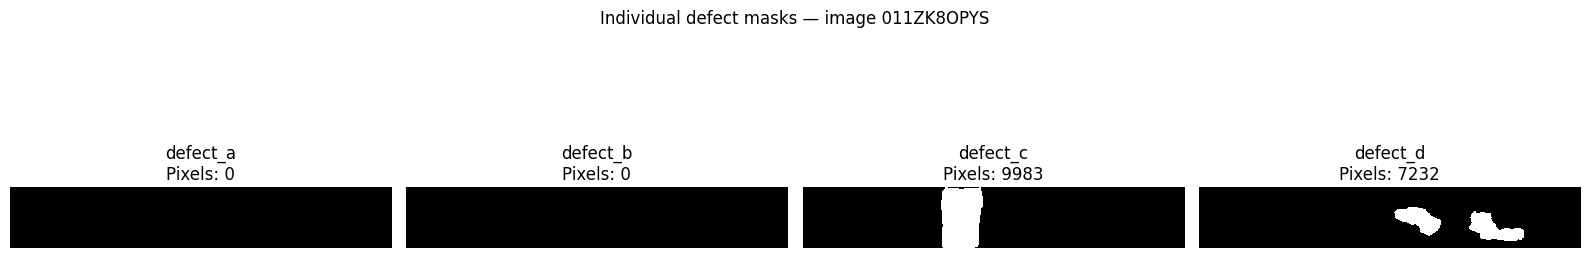

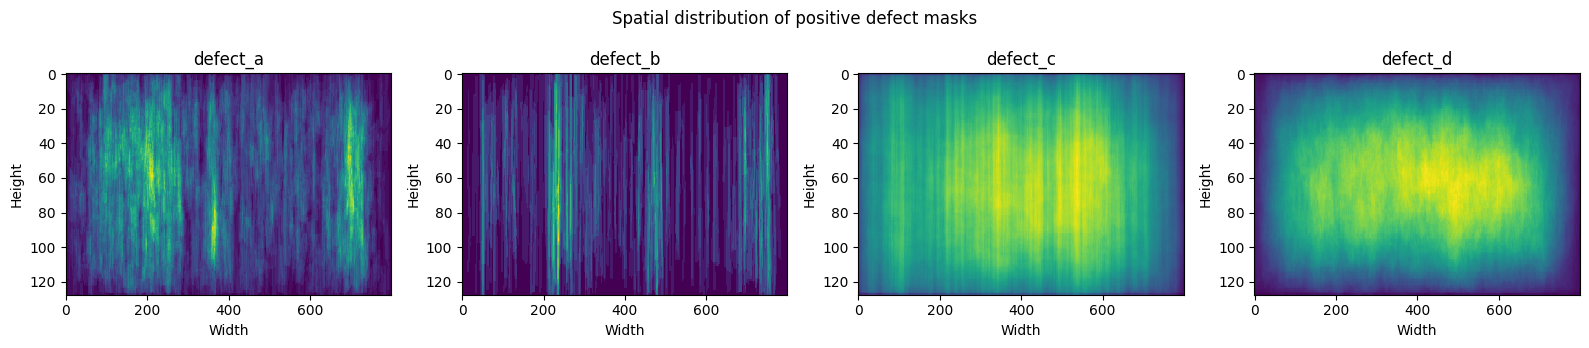

In [14]:

import matplotlib.pyplot as plt
import numpy as np

# Find an image containing at least two defect classes
multi_ids = (
    df.groupby("image_id")["has_defect"]
      .sum()
      .loc[lambda s: s > 1]
      .index
)

image_id = multi_ids[0]
group = df[df["image_id"] == image_id]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, (_, row) in zip(axes, group.iterrows()):
    mask = decode_rle(row["mask_rle"])
    ax.imshow(mask, cmap="gray", interpolation="nearest")
    ax.set_title(f'{row["defect_type"]}\nPixels: {int(mask.sum())}')
    ax.axis("off")

fig.suptitle(f"Individual defect masks — image {image_id}")
plt.tight_layout()
plt.show()

# Aggregate spatial heatmaps for each defect class
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))

for ax, defect_type in zip(
    axes, ["defect_a", "defect_b", "defect_c", "defect_d"]
):
    rows = df[
        (df["defect_type"] == defect_type) & df["has_defect"]
    ]

    heatmap = np.zeros((HEIGHT, WIDTH), dtype=np.float64)

    for rle in rows["mask_rle"]:
        heatmap += decode_rle(rle)

    ax.imshow(heatmap, aspect="auto", interpolation="nearest")
    ax.set_title(defect_type)
    ax.set_xlabel("Width")
    ax.set_ylabel("Height")

fig.suptitle("Spatial distribution of positive defect masks")
plt.tight_layout()
plt.show()


In [15]:

MAX_PIXELS = HEIGHT * WIDTH

rows_with_overrun = 0
runs_with_overrun = 0
max_end_index = 0
total_runs = 0

for rle in df["mask_rle"].dropna():
    rle = str(rle).strip()

    if not rle:
        continue

    values = np.fromstring(rle, sep=" ", dtype=np.int64)

    if len(values) % 2 != 0:
        print("WARNING: Odd number of RLE values:", rle[:100])
        continue

    starts = values[0::2]
    lengths = values[1::2]
    end_indices = starts + lengths - 1

    total_runs += len(end_indices)

    if len(end_indices) > 0:
        max_end_index = max(max_end_index, int(end_indices.max()))

    bad_runs = end_indices > MAX_PIXELS
    runs_with_overrun += int(bad_runs.sum())

    if bad_runs.any():
        rows_with_overrun += 1

print("Valid canvas pixel count:", MAX_PIXELS)
print("Total RLE runs checked:", total_runs)
print("Rows containing at least one overrun:", rows_with_overrun)
print("Individual runs exceeding the canvas:", runs_with_overrun)
print("Maximum RLE end index encountered:", max_end_index)


Valid canvas pixel count: 102400
Total RLE runs checked: 797406
Rows containing at least one overrun: 0
Individual runs exceeding the canvas: 0
Maximum RLE end index encountered: 102400


In [16]:

original_height, original_width = 128, 800
target_height, target_width = 256, 256

scale_y = target_height / original_height
scale_x = target_width / original_width
ratio = scale_y / scale_x

print("Vertical scale (sy):", scale_y)
print("Horizontal scale (sx):", scale_x)
print("Vertical stretch / horizontal compression ratio:", ratio)


Vertical scale (sy): 2.0
Horizontal scale (sx): 0.32
Vertical stretch / horizontal compression ratio: 6.25


In [17]:

import cv2
import numpy as np
from pathlib import Path

image_dir = base / "train"
classes = ["defect_a", "defect_b", "defect_c", "defect_d"]

# Accumulate intensity statistics without storing every pixel.
stats = {
    c: {
        "defect_n": 0, "defect_sum": 0.0, "defect_sq": 0.0,
        "bg_n": 0, "bg_sum": 0.0, "bg_sq": 0.0
    }
    for c in classes
}

missing_images = []
image_extensions = [".jpg", ".jpeg", ".png", ".tif", ".tiff"]

for image_id, group in df.groupby("image_id", sort=False):
    image_path = next(
        (image_dir / f"{image_id}{ext}"
         for ext in image_extensions
         if (image_dir / f"{image_id}{ext}").exists()),
        None
    )

    if image_path is None:
        missing_images.append(image_id)
        continue

    image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    if image is None or image.shape != (HEIGHT, WIDTH):
        print("WARNING: Could not load expected-size image:", image_path)
        continue

    for _, row in group.iterrows():
        c = row["defect_type"]
        mask = decode_rle(row["mask_rle"]).astype(bool)

        defect_pixels = image[mask].astype(np.float64)
        bg_pixels = image[~mask].astype(np.float64)

        s = stats[c]
        s["defect_n"] += defect_pixels.size
        s["defect_sum"] += defect_pixels.sum()
        s["defect_sq"] += np.square(defect_pixels).sum()
        s["bg_n"] += bg_pixels.size
        s["bg_sum"] += bg_pixels.sum()
        s["bg_sq"] += np.square(bg_pixels).sum()

def get_mean_var(n, total, total_sq):
    mean = total / n
    variance = max(0.0, (total_sq - total**2 / n) / (n - 1)) if n > 1 else 0.0
    return mean, variance

print("Missing image files:", len(missing_images))
print("\nCohen's d results (defect intensity minus background intensity):")

for c in classes:
    s = stats[c]
    n1, n2 = s["defect_n"], s["bg_n"]

    if n1 < 2 or n2 < 2:
        print(c, "Insufficient pixels")
        continue

    mean1, var1 = get_mean_var(n1, s["defect_sum"], s["defect_sq"])
    mean2, var2 = get_mean_var(n2, s["bg_sum"], s["bg_sq"])

    pooled_var = ((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2)
    pooled_std = np.sqrt(pooled_var)
    d = (mean1 - mean2) / pooled_std if pooled_std > 0 else np.nan

    print(
        f"{c}: d={d:.6f}, "
        f"defect_mean={mean1:.3f}, background_mean={mean2:.3f}"
    )


Missing image files: 0

Cohen's d results (defect intensity minus background intensity):
defect_a: d=0.176553, defect_mean=96.957, background_mean=88.474
defect_b: d=0.111320, defect_mean=93.828, background_mean=88.479
defect_c: d=0.383041, defect_mean=106.499, background_mean=88.121
defect_d: d=0.007413, defect_mean=88.833, background_mean=88.476


In [18]:
def dice_score(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=bool)
    y_pred = np.asarray(y_pred, dtype=bool)

    if y_true.sum() == 0 and y_pred.sum() == 0:
        return 1.0

    intersection = np.logical_and(y_true, y_pred).sum()
    return 2.0 * intersection / (y_true.sum() + y_pred.sum())

empty_gt = np.zeros((128, 800), dtype=bool)

# Model 1 predicts an empty mask
pred_empty = np.zeros_like(empty_gt)

# Model 2 predicts two stray pixels
pred_two_pixels = np.zeros_like(empty_gt)
pred_two_pixels[10, 10] = True
pred_two_pixels[20, 20] = True

print("Model 1 Dice:", dice_score(empty_gt, pred_empty))
print("Model 2 Dice:", dice_score(empty_gt, pred_two_pixels))

Model 1 Dice: 1.0
Model 2 Dice: 0.0


In [19]:

import cv2
import numpy as np
import pandas as pd

# Collect ground-truth connected-component areas for each defect class.
component_areas = {name: [] for name in ["defect_a", "defect_b",
                                         "defect_c", "defect_d"]}
total_gt_pixels = {name: 0 for name in component_areas}

for _, row in df.iterrows():
    defect = row["defect_type"]
    mask = decode_rle(row["mask_rle"])

    total_gt_pixels[defect] += int(mask.sum())

    if mask.sum() == 0:
        continue

    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        mask.astype(np.uint8), connectivity=8
    )

    # Label 0 is the background; process labels 1 onward.
    areas = stats[1:, cv2.CC_STAT_AREA]
    component_areas[defect].extend(areas.tolist())

# Q10: smallest component for defect_b
area_min_b = min(component_areas["defect_b"])

# Pixel-loss percentage for components strictly smaller than N.
def lost_pixel_percentage(defect, threshold):
    areas = np.asarray(component_areas[defect], dtype=np.int64)
    lost_pixels = areas[areas < threshold].sum()
    total_pixels = total_gt_pixels[defect]
    return 100.0 * lost_pixels / total_pixels

lost_b_50 = lost_pixel_percentage("defect_b", 50)
lost_a_200 = lost_pixel_percentage("defect_a", 200)

print("Smallest defect_b component area:", area_min_b)
print(f"defect_b pixels lost at N=50: {lost_b_50:.4f}%")
print(f"defect_a pixels lost at N=200: {lost_a_200:.4f}%")


Smallest defect_b component area: 93
defect_b pixels lost at N=50: 0.0000%
defect_a pixels lost at N=200: 15.2171%


In [20]:

from pathlib import Path
import pandas as pd

root = Path("/kaggle/input")

sample_files = list(root.rglob("sample_submission.csv"))
train_files = list(root.rglob("train.csv"))
test_dirs = [
    path for path in root.rglob("test")
    if path.is_dir()
]

print("SAMPLE SUBMISSION FILES")
for path in sample_files:
    print(path)

print("\nTRAIN ANNOTATION FILES")
for path in train_files:
    print(path)

print("\nTEST IMAGE DIRECTORIES")
for directory in test_dirs:
    count = sum(
        1 for path in directory.rglob("*")
        if path.is_file()
        and path.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )
    print(f"{directory} | images: {count}")

if not sample_files:
    raise FileNotFoundError(
        "sample_submission.csv not found under /kaggle/input"
    )

sample = pd.read_csv(
    sample_files[0],
    keep_default_na=False
)

print("\nSAMPLE SUBMISSION SHAPE:", sample.shape)
print("COLUMNS:", sample.columns.tolist())
print(sample.head(8).to_string(index=False))


SAMPLE SUBMISSION FILES
/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv

TRAIN ANNOTATION FILES
/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv

TEST IMAGE DIRECTORIES
/kaggle/input/competitions/industrial-surface-defect-detection/public/test | images: 3000

SAMPLE SUBMISSION SHAPE: (12000, 4)
COLUMNS: ['ID', 'image_id', 'defect_type', 'mask_rle']
 ID   image_id defect_type mask_rle
  1 WAFNKCRR7Q    defect_a         
  2 WAFNKCRR7Q    defect_b         
  3 WAFNKCRR7Q    defect_c         
  4 WAFNKCRR7Q    defect_d         
  5 YZXKEWSUDD    defect_a         
  6 YZXKEWSUDD    defect_b         
  7 YZXKEWSUDD    defect_c         
  8 YZXKEWSUDD    defect_d         


In [21]:
from pathlib import Path

for name in ["best.pt", "model_config.json"]:
    matches = list(Path("/kaggle/input").rglob(name))
    print(f"\n{name}:")
    if matches:
        for path in matches:
            print(f"FOUND: {path} ({path.stat().st_size:,} bytes)")
    else:
        print("NOT FOUND")


best.pt:
FOUND: /kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/best.pt (97,880,383 bytes)

model_config.json:
FOUND: /kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/model_config.json (813 bytes)


In [22]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [23]:
from pathlib import Path
import importlib.util
import subprocess
import sys
import json
import numpy as np
import pandas as pd
import torch
from PIL import Image

if importlib.util.find_spec("segmentation_models_pytorch") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "segmentation-models-pytorch"
    ])

import segmentation_models_pytorch as smp

MODEL_ROOT = Path("/kaggle/input/models")
TEST_DIR = Path(
    "/kaggle/input/competitions/"
    "industrial-surface-defect-detection/public/test"
)
SAMPLE_PATH = Path(
    "/kaggle/input/competitions/"
    "industrial-surface-defect-detection/public/sample_submission.csv"
)

CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
HEIGHT, WIDTH = 128, 800

checkpoint_matches = list(MODEL_ROOT.rglob("best.pt"))
if len(checkpoint_matches) != 1:
    raise RuntimeError(
        f"Expected one attached checkpoint, found {len(checkpoint_matches)}"
    )

CHECKPOINT_PATH = checkpoint_matches[0]
CONFIG_PATH = CHECKPOINT_PATH.parent / "model_config.json"

if not CONFIG_PATH.is_file():
    raise FileNotFoundError(f"Missing model config: {CONFIG_PATH}")

with CONFIG_PATH.open() as f:
    model_config = json.load(f)

if model_config["class_order"] != CLASSES:
    raise ValueError("Model class order does not match the expected order.")

if (model_config["height"], model_config["width"]) != (HEIGHT, WIDTH):
    raise ValueError("Model input dimensions do not match.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Checkpoint:", CHECKPOINT_PATH)
print("Checkpoint size:", f"{CHECKPOINT_PATH.stat().st_size:,} bytes")
print("SMP version:", __import__("importlib.metadata").metadata.version(
    "segmentation-models-pytorch"
))

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=1,
    classes=4,
    activation=None,
)

try:
    state_dict = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=True
    )
except TypeError:
    state_dict = torch.load(CHECKPOINT_PATH, map_location="cpu")

model.load_state_dict(state_dict, strict=True)
model = model.to(device).eval()

sample = pd.read_csv(SAMPLE_PATH, keep_default_na=False)
image_ids = sample["image_id"].drop_duplicates().head(4).tolist()
extensions = [".jpg", ".jpeg", ".png", ".tif", ".tiff"]

batch_images = []

for image_id in image_ids:
    image_path = next(
        (
            TEST_DIR / f"{image_id}{ext}"
            for ext in extensions
            if (TEST_DIR / f"{image_id}{ext}").is_file()
        ),
        None
    )

    if image_path is None:
        raise FileNotFoundError(f"Test image not found: {image_id}")

    with Image.open(image_path) as image:
        array = np.asarray(image.convert("L"), dtype=np.float32) / 255.0

    if array.shape != (HEIGHT, WIDTH):
        raise ValueError(
            f"Unexpected dimensions for {image_id}: {array.shape}"
        )

    array = (array - array.mean()) / max(float(array.std()), 0.05)
    batch_images.append(array)

batch = torch.from_numpy(
    np.stack(batch_images)[:, None].copy()
).to(device)

with torch.inference_mode():
    probabilities = torch.sigmoid(model(batch)).cpu().numpy()

if probabilities.shape != (len(image_ids), 4, HEIGHT, WIDTH):
    raise RuntimeError(f"Unexpected output shape: {probabilities.shape}")

if not np.isfinite(probabilities).all():
    raise RuntimeError("Predictions contain NaN or infinite values.")

print("\nInference smoke test passed.")
print("Input tensor shape:", tuple(batch.shape))
print("Output tensor shape:", probabilities.shape)
print("Probability range:", float(probabilities.min()), float(probabilities.max()))

for index, image_id in enumerate(image_ids):
    print(f"\nImage: {image_id}")
    for class_index, defect_type in enumerate(CLASSES):
        fraction = float(
            (probabilities[index, class_index] >= 0.5).mean()
        )
        print(f"  {defect_type}: predicted pixel fraction = {fraction:.6f}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.6/154.6 kB 3.0 MB/s eta 0:00:00
Device: cuda
GPU: Tesla T4
Checkpoint: /kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/best.pt
Checkpoint size: 97,880,383 bytes
SMP version: 0.6.0

Inference smoke test passed.
Input tensor shape: (4, 1, 128, 800)
Output tensor shape: (4, 4, 128, 800)
Probability range: 1.274132355177926e-08 0.9951377511024475

Image: WAFNKCRR7Q
  defect_a: predicted pixel fraction = 0.000000
  defect_b: predicted pixel fraction = 0.000000
  defect_c: predicted pixel fraction = 0.000000
  defect_d: predicted pixel fraction = 0.000000

Image: YZXKEWSUDD
  defect_a: predicted pixel fraction = 0.000137
  defect_b: predicted pixel fraction = 0.000078
  defect_c: predicted pixel fraction = 0.003330
  defect_d: predicted pixel fraction = 0.000000

Image: 0ATN06ZB48
  defect_a: predicted pixel fraction = 0.012666
  defect_b: predicted pixel fraction = 0.011279
  defect_c: predic

In [24]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
from PIL import Image
import segmentation_models_pytorch as smp

ROOT = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")
TEST_DIR = ROOT / "test"
SAMPLE_PATH = ROOT / "sample_submission.csv"
MODEL_DIR = Path("/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2")
CHECKPOINT = MODEL_DIR / "best.pt"
CONFIG_PATH = MODEL_DIR / "model_config.json"
OUTPUT_PATH = Path("/kaggle/working/submission_resnet34_unet_t050.csv")

CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
HEIGHT, WIDTH = 128, 800
THRESHOLD = 0.5
BATCH_SIZE = 8
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for path in [TEST_DIR, SAMPLE_PATH, CHECKPOINT, CONFIG_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Required path not found: {path}")

with CONFIG_PATH.open() as f:
    config = json.load(f)

if config["class_order"] != CLASSES:
    raise ValueError("Checkpoint class order does not match the submission classes.")

if (config["height"], config["width"]) != (HEIGHT, WIDTH):
    raise ValueError("Checkpoint dimensions do not match the expected image size.")

sample = pd.read_csv(SAMPLE_PATH, keep_default_na=False)
required_columns = ["ID", "image_id", "defect_type", "mask_rle"]

if sample.columns.tolist() != required_columns:
    raise ValueError(f"Unexpected submission columns: {sample.columns.tolist()}")

if len(sample) != 12000 or sample["image_id"].nunique() != 3000:
    raise ValueError("Unexpected sample submission dimensions.")

if set(sample["defect_type"].unique()) != set(CLASSES):
    raise ValueError("Sample submission defect classes do not match.")

def encode_rle(mask):
    pixels = np.asarray(mask, dtype=np.uint8).reshape(-1, order="F")
    padded = np.pad(pixels, (1, 1))
    changes = np.flatnonzero(padded[1:] != padded[:-1]) + 1

    if changes.size == 0:
        return ""

    runs = changes.copy()
    runs[1::2] -= runs[::2]
    return " ".join(map(str, runs.tolist()))

def decode_rle(rle, shape):
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)

    if not rle.strip():
        return flat.reshape(shape, order="F")

    values = np.fromstring(rle, sep=" ", dtype=np.int64)

    if len(values) % 2:
        raise ValueError("RLE must contain start-length pairs.")

    starts = values[0::2] - 1
    lengths = values[1::2]

    if np.any(starts < 0) or np.any(lengths <= 0):
        raise ValueError("Invalid RLE start or length.")

    for start, length in zip(starts, lengths):
        end = start + length
        if end > flat.size:
            raise ValueError("RLE exceeds the image dimensions.")
        flat[start:end] = 1

    return flat.reshape(shape, order="F")

toy = np.zeros((7, 9), dtype=np.uint8)
toy[1:4, 2] = 1
toy[5, 7:9] = 1

if not np.array_equal(toy, decode_rle(encode_rle(toy), toy.shape)):
    raise RuntimeError("RLE round-trip test failed.")

extensions = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
image_paths = {
    path.stem: path
    for path in TEST_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() in extensions
}

image_ids = sample["image_id"].drop_duplicates().tolist()
missing_ids = [image_id for image_id in image_ids if image_id not in image_paths]

if missing_ids:
    raise FileNotFoundError(
        f"{len(missing_ids)} test images could not be located. "
        f"Examples: {missing_ids[:5]}"
    )

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=1,
    classes=4,
    activation=None,
)

try:
    state_dict = torch.load(
        CHECKPOINT,
        map_location="cpu",
        weights_only=True,
    )
except TypeError:
    state_dict = torch.load(CHECKPOINT, map_location="cpu")

model.load_state_dict(state_dict, strict=True)
model.to(DEVICE).eval()

predictions = {}
positive_pixels = np.zeros(4, dtype=np.int64)
empty_masks = 0

for start in range(0, len(image_ids), BATCH_SIZE):
    batch_ids = image_ids[start:start + BATCH_SIZE]
    arrays = []

    for image_id in batch_ids:
        with Image.open(image_paths[image_id]) as image:
            array = np.asarray(image.convert("L"), dtype=np.float32) / 255.0

        if array.shape != (HEIGHT, WIDTH):
            raise ValueError(
                f"{image_id}: expected {(HEIGHT, WIDTH)}, got {array.shape}"
            )

        array = (array - array.mean()) / max(float(array.std()), 0.05)
        arrays.append(array)

    tensor = torch.from_numpy(
        np.stack(arrays)[:, None].copy()
    ).to(DEVICE)

    with torch.inference_mode():
        probabilities = torch.sigmoid(model(tensor)).cpu().numpy()

    if not np.isfinite(probabilities).all():
        raise RuntimeError("Model produced non-finite predictions.")

    for i, image_id in enumerate(batch_ids):
        for class_index, defect_type in enumerate(CLASSES):
            mask = probabilities[i, class_index] >= THRESHOLD
            positive_pixels[class_index] += int(mask.sum())

            if not mask.any():
                empty_masks += 1

            predictions[(image_id, defect_type)] = encode_rle(mask)

    completed = min(start + len(batch_ids), len(image_ids))

    if completed % 400 == 0 or completed == len(image_ids):
        print(f"Processed {completed}/{len(image_ids)} images")

if len(predictions) != len(sample):
    raise RuntimeError(
        f"Expected {len(sample)} predictions; got {len(predictions)}."
    )

submission = sample.copy()
submission["mask_rle"] = [
    predictions[(image_id, defect_type)]
    for image_id, defect_type in zip(
        sample["image_id"], sample["defect_type"]
    )
]

if submission.isna().any().any():
    raise ValueError("Submission contains missing values.")

if submission[["image_id", "defect_type"]].duplicated().any():
    raise ValueError("Duplicate image/category combinations found.")

submission.to_csv(OUTPUT_PATH, index=False)

check = pd.read_csv(OUTPUT_PATH, keep_default_na=False)

if not check.equals(submission):
    raise RuntimeError("Saved submission does not match the generated dataframe.")

print("\nSubmission created and verified.")
print("Output:", OUTPUT_PATH)
print("Shape:", check.shape)
print("Columns:", check.columns.tolist())
print("Unique images:", check["image_id"].nunique())
print("Threshold:", THRESHOLD)
print("Empty masks:", empty_masks, "of", len(check))
print("Predicted foreground pixels by class:", dict(zip(CLASSES, positive_pixels)))
print(check.head(8).to_string(index=False))

Processed 400/3000 images
Processed 800/3000 images
Processed 1200/3000 images
Processed 1600/3000 images
Processed 2000/3000 images
Processed 2400/3000 images
Processed 2800/3000 images
Processed 3000/3000 images

Submission created and verified.
Output: /kaggle/working/submission_resnet34_unet_t050.csv
Shape: (12000, 4)
Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
Unique images: 3000
Threshold: 0.5
Empty masks: 2915 of 12000
Predicted foreground pixels by class: {'defect_a': np.int64(1517367), 'defect_b': np.int64(1387223), 'defect_c': np.int64(4411121), 'defect_d': np.int64(10527190)}
 ID   image_id defect_type                                                                                                                                                                                                   mask_rle
  1 WAFNKCRR7Q    defect_a                                                                                                                                           

In [25]:
from pathlib import Path
import pandas as pd

root = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")
working = Path("/kaggle/working")

sample_path = root / "sample_submission.csv"
model_path = working / "submission_resnet34_unet_t050.csv"
final_path = working / "submission.csv"

if not model_path.is_file():
    raise FileNotFoundError(
        f"Trained-model predictions not found: {model_path}"
    )

sample = pd.read_csv(sample_path, keep_default_na=False)
predictions = pd.read_csv(model_path, keep_default_na=False)

expected_columns = ["ID", "image_id", "defect_type", "mask_rle"]

if predictions.columns.tolist() != expected_columns:
    raise ValueError("Trained-model submission has incorrect columns.")

if len(predictions) != 12000 or len(sample) != 12000:
    raise ValueError("Unexpected submission row count.")

if not predictions[expected_columns[:3]].equals(sample[expected_columns[:3]]):
    raise ValueError("Prediction IDs or row order do not match the sample.")

nonempty = predictions["mask_rle"].astype(str).str.strip().ne("").sum()

if nonempty == 0:
    raise ValueError(
        "Every predicted mask is empty. Do not submit this file yet."
    )

predictions.to_csv(final_path, index=False)

verified = pd.read_csv(final_path, keep_default_na=False)

if not verified.equals(predictions):
    raise RuntimeError("Final submission verification failed.")

print("Final trained-model submission created.")
print("File:", final_path)
print("Rows:", len(verified))
print("Non-empty predicted masks:", nonempty)
print("Empty predicted masks:", len(verified) - nonempty)
print("Columns:", verified.columns.tolist())
print(verified.head(8).to_string(index=False))

Final trained-model submission created.
File: /kaggle/working/submission.csv
Rows: 12000
Non-empty predicted masks: 9085
Empty predicted masks: 2915
Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
 ID   image_id defect_type                                                                                                                                                                                                   mask_rle
  1 WAFNKCRR7Q    defect_a                                                                                                                                                                                                           
  2 WAFNKCRR7Q    defect_b                                                                                                                                                                                                           
  3 WAFNKCRR7Q    defect_c                                                                                

In [26]:
from pathlib import Path
import csv
import pandas as pd

root = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")
sample_path = root / "sample_submission.csv"

source_path = Path("/kaggle/working/submission_resnet34_unet_t050.csv")
output_path = Path("/kaggle/working/submission.csv")

if not source_path.is_file():
    raise FileNotFoundError(f"Trained-model submission not found: {source_path}")

sample = pd.read_csv(sample_path, keep_default_na=False)
submission = pd.read_csv(source_path, keep_default_na=False)

expected_columns = ["ID", "image_id", "defect_type", "mask_rle"]

if submission.columns.tolist() != expected_columns:
    raise ValueError(f"Unexpected columns: {submission.columns.tolist()}")

if len(submission) != len(sample):
    raise ValueError("Submission row count does not match the sample.")

if not submission[["ID", "image_id", "defect_type"]].equals(
    sample[["ID", "image_id", "defect_type"]]
):
    raise ValueError("Submission IDs or row order differ from the sample.")

empty_mask = submission["mask_rle"].astype(str).str.strip().eq("")
submission.loc[empty_mask, "mask_rle"] = " "

submission.to_csv(
    output_path,
    index=False,
    quoting=csv.QUOTE_ALL,
)

verified = pd.read_csv(output_path)

if verified.isna().any().any():
    raise ValueError(
        f"Null values remain:\n{verified.isna().sum()}"
    )

if len(verified) != 12000:
    raise ValueError("Expected exactly 12,000 prediction rows.")

print("Submission validated successfully.")
print("File:", output_path)
print("Rows:", len(verified))
print("Null values:", int(verified.isna().sum().sum()))
print(
    "Empty masks represented by spaces:",
    int(verified["mask_rle"].astype(str).str.strip().eq("").sum())
)
print("Columns:", verified.columns.tolist())

Submission validated successfully.
File: /kaggle/working/submission.csv
Rows: 12000
Null values: 0
Empty masks represented by spaces: 2915
Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
